# Fourierova analýza hry EXACT FORCE (balanced force): pacient vs. zdravý

**Úloha:** zobrať dáta z hry *balanced force* (v dátach `EXACT_FORCE`), urobiť ukážku Fourierovej analýzy
na dvoch ľuďoch (jeden pacient, jeden zdravý), ukázať rozdiely pri dĺžkach okna signálu **3, 5 a 10 s**
a urobiť **spektrogram** pre oboch.

**Hra EXACT FORCE:** subjekt drží prstami oboch rúk malú konštantnú silu, 4 opakovania (iterácie) po 16 s.
Je to vhodná úloha na detekciu trasu: ak má človek držať silu rovnomerne, chvenie sa prejaví ako
periodické kolísanie sily. Parkinsonský tras má typicky frekvenciu ~4–6 Hz, fyziologický tras ~8–12 Hz.

## 1. Výber súborov

Označenie pacient/zdravý nie je v nameraných súboroch, je v CSV súboroch v priečinku `datasets`:

| | Pacient | Zdravý |
|---|---|---|
| CSV | `dataset_patients.csv` | `dataset_99.csv` |
| `patient_id` | `ILHC-BZCP` | `992612` |
| vek, pohlavie | 73, žena | 74, žena |
| `measurement_id` | `340209e1-ecf2-4446-a52a-16c5a830241b` | `de72d25f-8f60-4820-a784-68c0f3d0b7a3` |
| `step_id` EXACT_FORCE | `d2e6b7bd-…` | `5867ebbc-…` |
| súbor | `22_08_2025/results_340209e1-…_20250424-112532` | `9_9_2026/results_de72d25f-…_20260909-153121` |

Pacienti a zdraví boli meraní rôznymi verziami scenára, preto má EXACT_FORCE iný `step_id`;
dĺžka je rovnaká (4 × 16 s). Zdravý subjekt bol zvolený s rovnakým pohlavím a podobným vekom, aby rozdiel
nebol spôsobený vekom. Pacientka bola vybraná ako prípad s najvýraznejším trasom spomedzi pacientov
(predbežný skríning všetkých súborov EXACT_FORCE); diagnóza v datasete uvedená nie je.

Nasledujúca bunka výber overí priamo z CSV a zo súborov.

In [1]:
import glob
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from scipy.signal import detrend, get_window, spectrogram

from rehapiano_io import FINGER_CHANNELS, channel_label, load_measurement

ROOT = Path(".")
PEOPLE = {
    "Pacient": dict(csv="dataset_patients.csv", pid="ILHC-BZCP", folder="22_08_2025",
                    exam="340209e1-ecf2-4446-a52a-16c5a830241b"),
    "Zdravý": dict(csv="dataset_99.csv", pid="992612", folder="9_9_2026",
                   exam="de72d25f-8f60-4820-a784-68c0f3d0b7a3"),
}

rows = []
for who, p in PEOPLE.items():
    df = pd.read_csv(ROOT / "datasets" / p["csv"], sep=";")
    r = df[(df.patient_id.astype(str) == p["pid"]) & (df.measurement_id == p["exam"])
           & (df.step_type == "EXACT_FORCE")].iloc[0]
    p["step_id"] = r.step_id
    rows.append(dict(skupina=who, patient_id=r.patient_id, vek=r.age, pohlavie=r.gender,
                     datum=r.timestamp, step_type=r.step_type, step_id=r.step_id))
display(pd.DataFrame(rows))

,skupina,patient_id,vek,pohlavie,datum,step_type,step_id
0,Pacient,ILHC-BZCP,73,female,2025-04-24 11:31:44,EXACT_FORCE,d2e6b7bd-a952-4652-afe3-9888e29ac205
1,Zdravý,992612,74,female,9/9/2026 15:41:10,EXACT_FORCE,5867ebbc-a463-4d20-8b20-50df7c64ace7


Súbory jedného vyšetrenia majú v názve rovnaké `measurement_id`; súbor hry EXACT_FORCE nájdeme podľa
`step_id` vo vnútri súboru (je to prvý súbor vyšetrenia, ~2,8 MB).

In [2]:
import json, re

def find_step_file(folder, exam, step_id):
    for f in sorted(glob.glob(str(ROOT / folder / f"results_{exam}_*"))):
        with open(f, "rb") as fh:
            head = fh.read(400).decode("ascii", "ignore")
        if re.search(r'"step_id":\s*"' + step_id, head):
            return Path(f)
    raise FileNotFoundError(f"{exam} / {step_id}")

for who, p in PEOPLE.items():
    p["file"] = find_step_file(p["folder"], p["exam"], p["step_id"])
    print(f"{who:8s} {p['file']}")

Pacient  22_08_2025\results_340209e1-ecf2-4446-a52a-16c5a830241b_20250424-112532
Zdravý   9_9_2026\results_de72d25f-8f60-4820-a784-68c0f3d0b7a3_20260909-153121


## 2. Načítanie dát

Formát súboru: JSON → pole `raw` → base64 → zlib → pickle → 4 iterácie → pakety po 72 bajtoch
(8 B čas ako **int64** v ms + 16 × float32 kanálov). Pozor: pôvodný `rehapiano_data_converter.py`
číta čas ako `double`, čo pre tieto dáta dáva nezmyselné časy; preto používame vlastný modul `rehapiano_io.py`.

Využité kanály: **0–4 ľavá ruka, 8–12 pravá ruka**. Hodnoty sú v relatívnych jednotkách (rozsah −1…1).

Časové značky nie sú rovnomerné (pakety prichádzajú v dávkach, rozdiely 0–5 ms), preto každú iteráciu
prevzorkujeme na rovnomernú mriežku **1000 Hz** (priemer v 1 ms košoch, prázdne koše a NaN doplnené
lineárnou interpoláciou). Každá iterácia je **samostatný záznam** – iterácie nespájame, medzi nimi je pauza.

In [3]:
FS = 1000.0
data = {who: load_measurement(p["file"], fs=FS) for who, p in PEOPLE.items()}

info = []
for who, m in data.items():
    for i, it in enumerate(m.iterations, start=1):
        info.append(dict(skupina=who, iteracia=i, paketov=it.n_raw, dlzka_s=round(it.t[-1], 2),
                         doplnenych_NaN=it.n_nan))
display(pd.DataFrame(info))

,skupina,iteracia,paketov,dlzka_s,doplnenych_NaN
0,Pacient,1,16038,16.03,75
1,Pacient,2,16036,16.02,100
2,Pacient,3,16037,16.03,50
3,Pacient,4,16044,16.04,55
4,Zdravý,1,16058,16.02,355
5,Zdravý,2,16055,16.03,250
6,Zdravý,3,16047,16.03,175
7,Zdravý,4,16059,16.03,255


### Nastavenia grafov a spoločné funkcie

In [4]:
SURFACE, INK, INK2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
COLORS = {"Zdravý": "#2a78d6", "Pacient": "#eb6834"}
SEQ = LinearSegmentedColormap.from_list(
    "seq_blue", ["#fcfcfb", "#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 1.6, "font.size": 10, "axes.titlesize": 11, "legend.frameon": False,
    "figure.dpi": 110,
})
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

TREMOR_BAND = (3.5, 12.0)      # pásmo, v ktorom hľadáme trasový vrchol
BANDS = [((4, 6), "4–6 Hz\nparkinsonský"), ((8, 12), "8–12 Hz\nfyziologický")]


def amplitude_spectrum(x, fs=FS):
    # Jednostranné amplitúdové spektrum: lineárny detrend, Hannovo okno, korekcia zisku okna.
    n = len(x)
    w = get_window("hann", n)
    y = detrend(x, type="linear") * w
    f = np.fft.rfftfreq(n, 1 / fs)
    a = np.abs(np.fft.rfft(y)) / (n * w.mean())
    a[1:] *= 2
    return f, a


def tremor_peak(f, a, band=TREMOR_BAND):
    m = (f >= band[0]) & (f <= band[1])
    k = np.argmax(a[m])
    return f[m][k], a[m][k], float(np.sum(a[m] ** 2))


def shade_bands(ax, labels=True):
    for (lo, hi), text in BANDS:
        ax.axvspan(lo, hi, color="#898781", alpha=0.10, lw=0)
        if labels:
            ax.text((lo + hi) / 2, 0.97, text, transform=ax.get_xaxis_transform(),
                    ha="center", va="top", fontsize=8, color=INK2)

## 3. Pohľad na signál

Na začiatku každej iterácie subjekt silu ešte len nastavuje (prechodový dej) a na konci ju uvoľňuje.
Do analýzy preto berieme úsek **3 s – 15 s** každej iterácie (12 s), z ktorého sa zmestí aj 10 s okno.

Najprv porovnáme, **na ktorých prstoch** je kolísanie sily v pásme trasu najsilnejšie (výkon v pásme
3,5–12 Hz, priemer zo 4 iterácií):

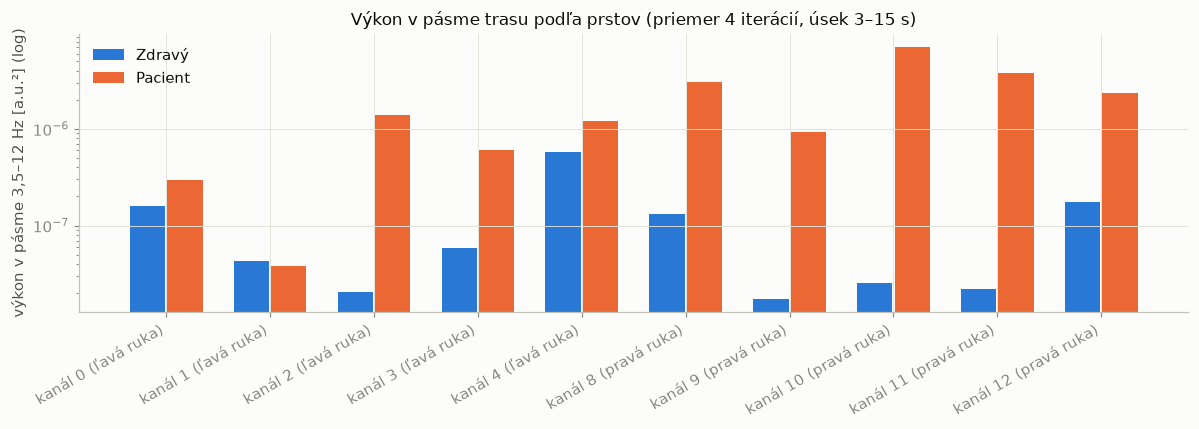

Najsilnejší kanál u pacienta: kanál 10 (pravá ruka)
Pomer výkonu pacient / zdravý na tomto kanáli: 278×
Pomer k najsilnejšiemu kanálu zdravého: 12×


In [5]:
T0, T1 = 3.0, 15.0
i0, i1 = int(T0 * FS), int(T1 * FS)

band_power = {}
for who, m in data.items():
    bp = np.zeros(len(FINGER_CHANNELS))
    for it in m.iterations:
        for c in range(len(FINGER_CHANNELS)):
            f, a = amplitude_spectrum(it.x[i0:i1, c])
            bp[c] += tremor_peak(f, a)[2] / len(m.iterations)
    band_power[who] = bp

labels = [channel_label(c) for c in range(len(FINGER_CHANNELS))]
fig, ax = plt.subplots(figsize=(11, 4))
xs = np.arange(len(labels))
for k, who in enumerate(["Zdravý", "Pacient"]):
    ax.bar(xs + (k - 0.5) * 0.36, band_power[who], width=0.34, color=COLORS[who], label=who)
ax.set_yscale("log")
ax.set_xticks(xs, labels, rotation=30, ha="right")
ax.set_ylabel("výkon v pásme 3,5–12 Hz [a.u.²] (log)")
ax.set_title("Výkon v pásme trasu podľa prstov (priemer 4 iterácií, úsek 3–15 s)")
ax.legend()
fig.tight_layout(); fig.savefig(FIG_DIR / "01_vykon_podla_prstov.png", dpi=150); plt.show()

CH = int(np.argmax(band_power["Pacient"]))
print(f"Najsilnejší kanál u pacienta: {channel_label(CH)}")
print(f"Pomer výkonu pacient / zdravý na tomto kanáli: {band_power['Pacient'][CH] / band_power['Zdravý'][CH]:.0f}×")
print(f"Pomer k najsilnejšiemu kanálu zdravého: {band_power['Pacient'][CH] / band_power['Zdravý'].max():.0f}×")

Ďalej analyzujeme **ten istý kanál u oboch ľudí** (kanál s najsilnejším trasom u pacienta), aby bolo
porovnanie férové. Na ukážku okien použijeme **2. iteráciu** (prvá iterácia slúži aj ako zácvik);
výsledky všetkých štyroch iterácií sú v tabuľke v časti 5.

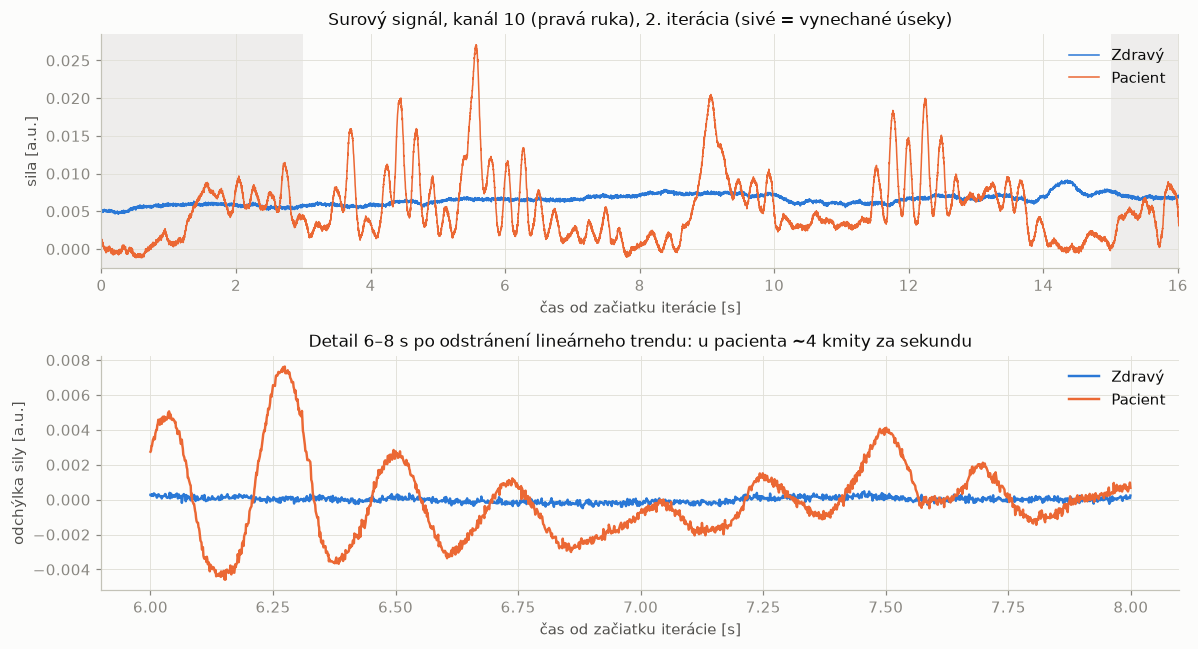

In [6]:
IT = 1  # index iterácie (0 = prvá) -> 2. iterácia

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=False)
ax = axes[0]
for who in ["Zdravý", "Pacient"]:
    it = data[who].iterations[IT]
    ax.plot(it.t, it.x[:, CH], color=COLORS[who], label=who, lw=1.0)
ax.axvspan(0, T0, color=MUTED, alpha=0.12, lw=0)
ax.axvspan(T1, it.t[-1], color=MUTED, alpha=0.12, lw=0)
ax.set_xlim(0, it.t[-1])
ax.set_title(f"Surový signál, {channel_label(CH)}, 2. iterácia (sivé = vynechané úseky)")
ax.set_xlabel("čas od začiatku iterácie [s]"); ax.set_ylabel("sila [a.u.]"); ax.legend(loc="upper right")

ax = axes[1]
z0, z1 = 6.0, 8.0     # 2 s výrez, pomalý trend odstránený
for who in ["Zdravý", "Pacient"]:
    it = data[who].iterations[IT]
    seg = slice(int(z0 * FS), int(z1 * FS))
    ax.plot(it.t[seg], detrend(it.x[seg, CH], type="linear"), color=COLORS[who], label=who)
ax.set_title(f"Detail {z0:.0f}–{z1:.0f} s po odstránení lineárneho trendu: u pacienta ~4 kmity za sekundu")
ax.set_xlabel("čas od začiatku iterácie [s]"); ax.set_ylabel("odchýlka sily [a.u.]"); ax.legend(loc="upper right")
fig.tight_layout(); fig.savefig(FIG_DIR / "02_signal.png", dpi=150); plt.show()

## 4. Fourierova analýza pri rôznych dĺžkach okna (3, 5, 10 s)

Všetky tri okná začínajú v **rovnakom čase (3 s)** tej istej iterácie: 3–6 s, 3–8 s a 3–13 s.
Rozdiel je teda len v dĺžke okna $T$. Spracovanie: lineárny detrend → Hannovo okno → FFT →
jednostranné amplitúdové spektrum.

Frekvenčné rozlíšenie (vzdialenosť bodov spektra) je $\Delta f = 1/T$:

In [7]:
WINDOWS = [3, 5, 10]
display(pd.DataFrame({"okno T [s]": WINDOWS, "vzoriek N": [int(w * FS) for w in WINDOWS],
                      "Δf = 1/T [Hz]": [round(1 / w, 3) for w in WINDOWS]}))

,okno T [s],vzoriek N,Δf = 1/T [Hz]
0,3,3000,0.333
1,5,5000,0.200
2,10,10000,0.100


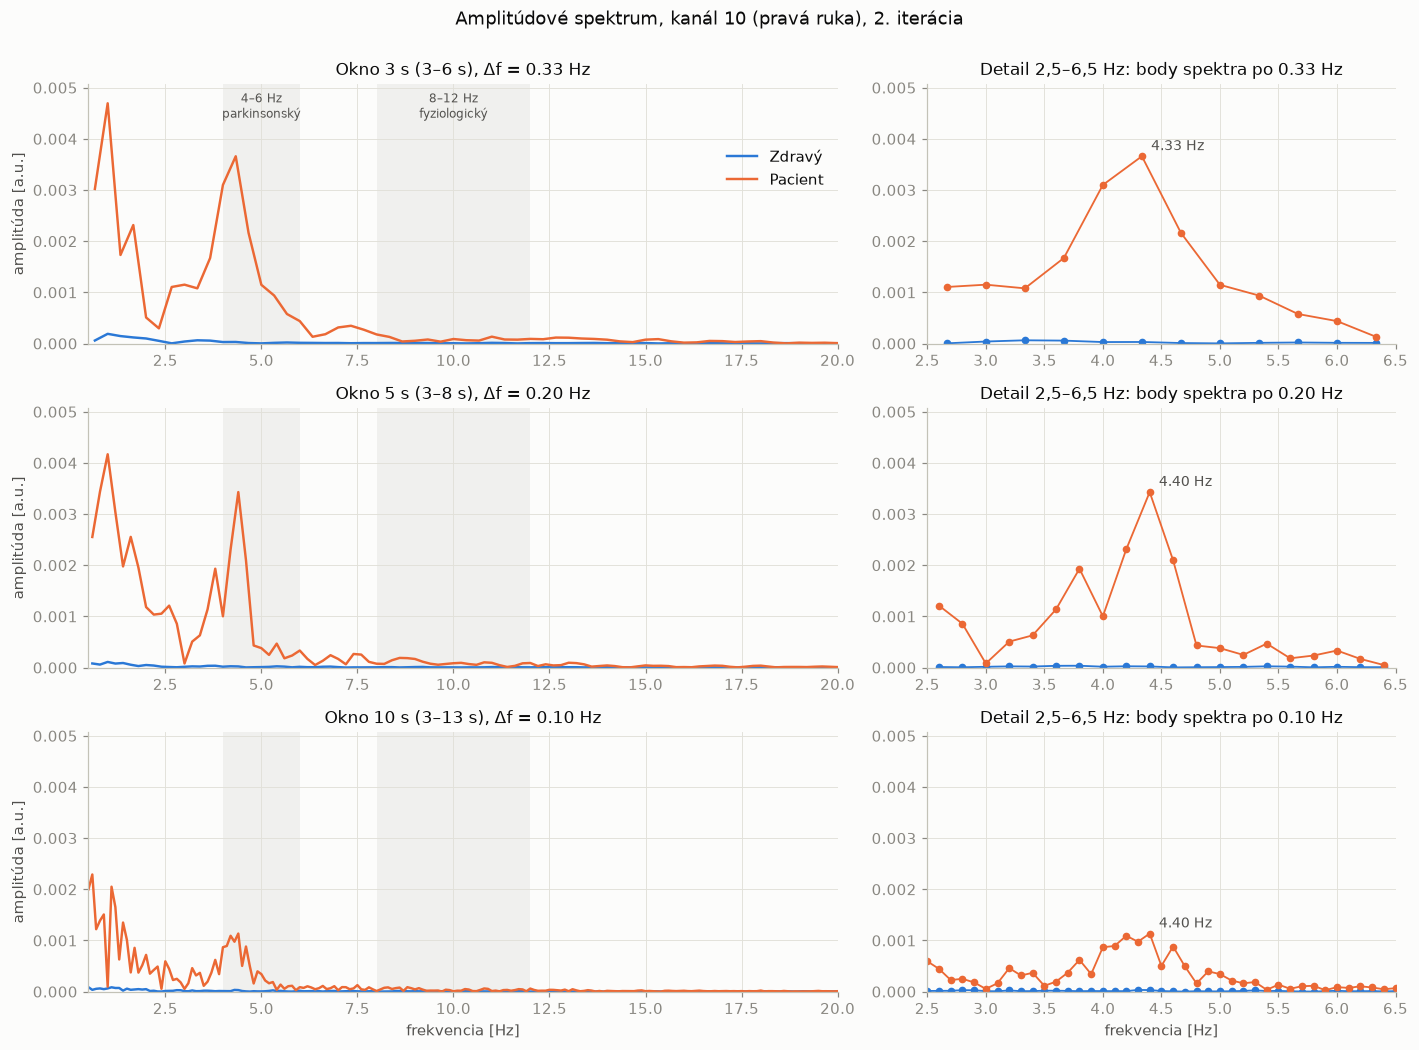

f_vrchol_Hz        amplituda_1e3       
skupina     Pacient Zdravý       Pacient Zdravý
okno_s                                         
3              4.33   3.67         3.660  0.056
5              4.40   3.80         3.430  0.036
10             4.40   4.30         1.135  0.034

In [8]:
fig, axes = plt.subplots(len(WINDOWS), 2, figsize=(13, 9.5), gridspec_kw=dict(width_ratios=[1.6, 1]))
peaks = []
ymax = 0
spectra = {}
for who in ["Zdravý", "Pacient"]:
    x = data[who].iterations[IT].x[:, CH]
    for w in WINDOWS:
        f, a = amplitude_spectrum(x[i0:i0 + int(w * FS)])
        spectra[(who, w)] = (f, a)
        ymax = max(ymax, a[(f >= 1) & (f <= 20)].max())

for r, w in enumerate(WINDOWS):
    for who in ["Zdravý", "Pacient"]:
        f, a = spectra[(who, w)]
        fd, ad, _ = tremor_peak(f, a)
        peaks.append(dict(okno_s=w, skupina=who, f_vrchol_Hz=round(fd, 2), amplituda_1e3=round(ad * 1e3, 3)))
        m = (f >= 0.5) & (f <= 20)
        axes[r, 0].plot(f[m], a[m], color=COLORS[who], label=who)
        z = (f >= 2.5) & (f <= 6.5)
        axes[r, 1].plot(f[z], a[z], color=COLORS[who], marker="o", ms=4, lw=1.2, label=who)
        if who == "Pacient":
            axes[r, 1].annotate(f"{fd:.2f} Hz", (fd, ad), textcoords="offset points", xytext=(6, 4),
                                fontsize=9, color=INK2)
    shade_bands(axes[r, 0], labels=(r == 0))
    axes[r, 0].set_xlim(0.5, 20); axes[r, 0].set_ylim(0, ymax * 1.08)
    axes[r, 1].set_xlim(2.5, 6.5); axes[r, 1].set_ylim(0, ymax * 1.08)
    axes[r, 0].set_title(f"Okno {w} s (3–{3 + w} s), Δf = {1 / w:.2f} Hz")
    axes[r, 1].set_title(f"Detail 2,5–6,5 Hz: body spektra po {1 / w:.2f} Hz")
    axes[r, 0].set_ylabel("amplitúda [a.u.]")
axes[0, 0].legend(loc="upper right", bbox_to_anchor=(1, 0.8))
axes[-1, 0].set_xlabel("frekvencia [Hz]"); axes[-1, 1].set_xlabel("frekvencia [Hz]")
fig.suptitle(f"Amplitúdové spektrum, {channel_label(CH)}, 2. iterácia", y=1.0)
fig.tight_layout(); fig.savefig(FIG_DIR / "03_spektra_okna.png", dpi=150); plt.show()

display(pd.DataFrame(peaks).pivot(index="okno_s", columns="skupina"))

## 5. Stabilita výsledku vo všetkých 4 iteráciách

Pre každú iteráciu, okno a osobu: frekvencia najvyššieho vrcholu v pásme 3,5–12 Hz a jeho amplitúda
(`amplituda_1e3` = amplitúda × 10³, aby boli viditeľné aj malé hodnoty zdravej osoby). Ak je vrchol pacienta skutočný tras, mal by sa opakovať pri rovnakej frekvencii.

In [9]:
rows = []
for who in ["Zdravý", "Pacient"]:
    for i, it in enumerate(data[who].iterations, start=1):
        for w in WINDOWS:
            f, a = amplitude_spectrum(it.x[i0:i0 + int(w * FS), CH])
            fd, ad, bp = tremor_peak(f, a)
            rows.append(dict(skupina=who, iteracia=i, okno_s=w, f_vrchol_Hz=round(fd, 2),
                             amplituda_1e3=ad * 1e3, vykon_pasma=bp))
stab = pd.DataFrame(rows)
display(stab.pivot_table(index=["skupina", "iteracia"], columns="okno_s",
                         values=["f_vrchol_Hz", "amplituda_1e3"]).round(3))

summary = stab.groupby(["skupina", "okno_s"]).agg(
    f_priemer=("f_vrchol_Hz", "mean"), f_std=("f_vrchol_Hz", "std"),
    amplituda_1e3_priemer=("amplituda_1e3", "mean")).round(3)
display(summary)

amplituda_1e3               f_vrchol_Hz          
okno_s                      3      5      10          3    5    10
skupina iteracia                                                  
Pacient 1                0.733  1.242  0.929        4.67  4.0  4.1
        2                3.660  3.430  1.135        4.33  4.4  4.4
        3                0.453  0.191  0.761        4.33  4.4  4.0
        4                0.589  1.961  1.419        4.00  4.2  3.6
Zdravý  1                0.477  0.288  0.100        4.00  3.8  3.6
        2                0.056  0.036  0.034        3.67  3.8  4.3
        3                0.022  0.020  0.045        4.00  5.6  4.7
        4                0.035  0.030  0.022        5.00  3.6  4.1

f_priemer  f_std  amplituda_1e3_priemer
skupina okno_s                                         
Pacient 3           4.332  0.274                  1.359
        5           4.250  0.191                  1.706
        10          4.025  0.330                  1.061
Zdravý  3           4.168  0.576                  0.148
        5           4.200  0.938                  0.093
        10          4.175  0.457                  0.050

## 6. Spektrogram

Spektrogram (krátkodobá Fourierova transformácia) ukazuje, ako sa spektrum mení v čase.
Nastavenia: okno **2 s** (Hann, Δf = 0,5 Hz), posun 0,2 s (90 % prekrytie), lineárny detrend v každom okne,
výkonová spektrálna hustota v dB. Obe osoby majú **rovnakú farebnú škálu**. Každá iterácia je
zobrazená samostatne (úsek 3–15 s), iterácie sa nespájajú.

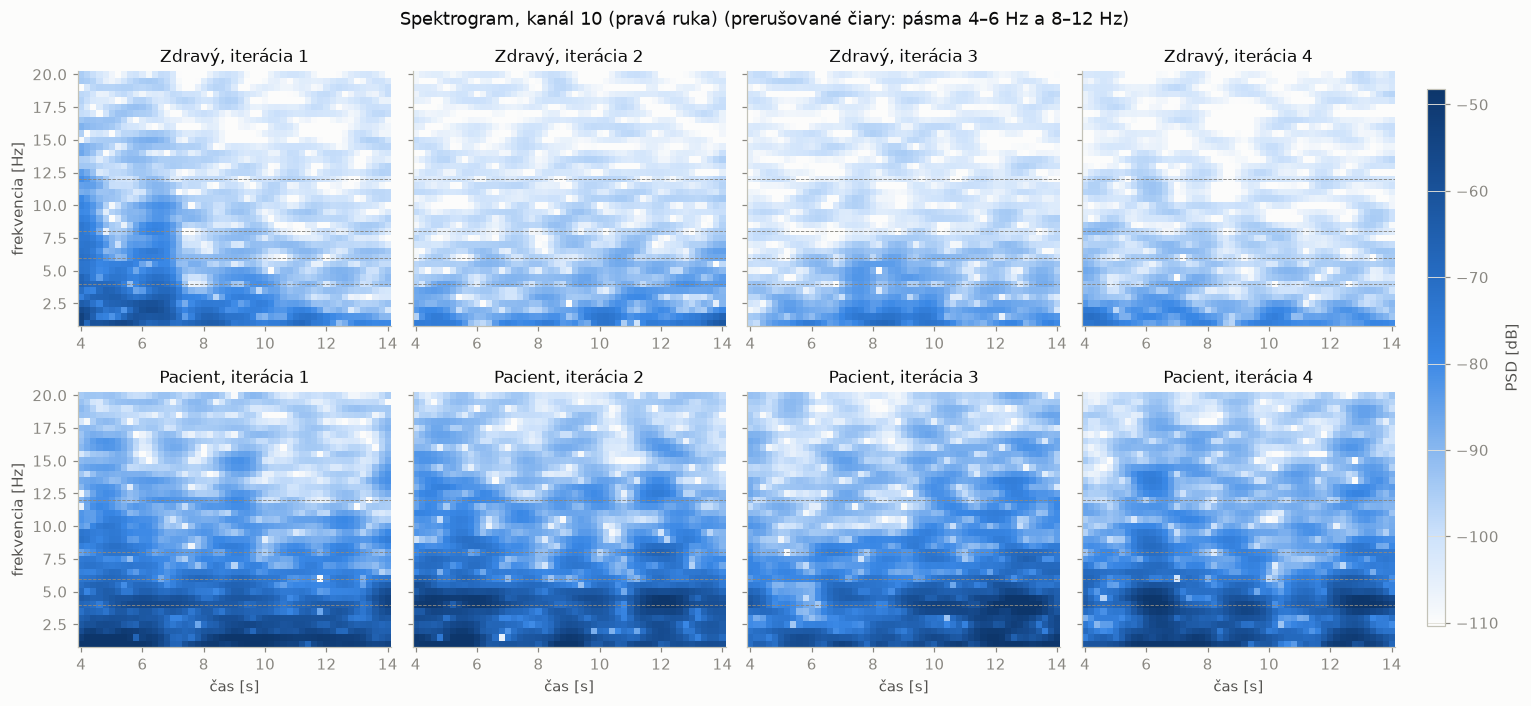

In [10]:
SPEC_WIN = 2.0
nper = int(SPEC_WIN * FS)
spec = {}
for who in ["Zdravý", "Pacient"]:
    for i, it in enumerate(data[who].iterations):
        f, t, S = spectrogram(it.x[i0:i1, CH], fs=FS, window="hann", nperseg=nper,
                              noverlap=nper - int(0.2 * FS), detrend="linear", scaling="density")
        spec[(who, i)] = (f, t + T0, 10 * np.log10(S + 1e-20))

fmax = 20
vals = np.concatenate([S[(f >= 1) & (f <= fmax)].ravel() for f, _, S in spec.values()])
vmin, vmax = np.percentile(vals, [5, 99.5])

fig, axes = plt.subplots(2, 4, figsize=(14, 6.5), sharey=True)
for r, who in enumerate(["Zdravý", "Pacient"]):
    for i in range(4):
        f, t, S = spec[(who, i)]
        m = (f >= 1) & (f <= fmax)
        im = axes[r, i].pcolormesh(t, f[m], S[m], shading="nearest", cmap=SEQ, vmin=vmin, vmax=vmax)
        axes[r, i].set_title(f"{who}, iterácia {i + 1}")
        axes[r, i].grid(False)
        for (lo, hi), _ in BANDS:
            axes[r, i].axhline(lo, color=MUTED, lw=0.6, ls="--"); axes[r, i].axhline(hi, color=MUTED, lw=0.6, ls="--")
        if r == 1: axes[r, i].set_xlabel("čas [s]")
    axes[r, 0].set_ylabel("frekvencia [Hz]")
fig.suptitle(f"Spektrogram, {channel_label(CH)} (prerušované čiary: pásma 4–6 Hz a 8–12 Hz)")
fig.tight_layout(rect=(0, 0, 0.92, 1))
cax = fig.add_axes([0.93, 0.12, 0.012, 0.75])
fig.colorbar(im, cax=cax, label="PSD [dB]")
fig.savefig(FIG_DIR / "04_spektrogram.png", dpi=150); plt.show()

## 7. Zhrnutie

**Rozdiel pacient vs. zdravý**
- U pacientky je pri držaní sily periodické kolísanie s frekvenciou **~4–4,4 Hz**, najsilnejšie na prstoch
  pravej ruky (kanál 10). To zodpovedá pásmu parkinsonského trasu. V časovom signáli je vidieť ~4 kmity
  za sekundu, tras prichádza v epizódach (zhluky kmitov).
- Na kanáli 10 je výkon v pásme 3,5–12 Hz u pacientky ~280× vyšší ako u zdravej osoby a ~12× vyšší ako na
  najaktívnejšom prste zdravej osoby.
- Frekvencia vrcholu pacientky je stabilná naprieč iteráciami (priemer 4,0–4,3 Hz, smerodajná odchýlka
  0,2–0,3 Hz). U zdravej osoby výrazný vrchol nie je: „najvyšší bod" v pásme náhodne skáče medzi 3,6 a 5,6 Hz
  (smerodajná odchýlka 0,5–0,9 Hz) a jeho amplitúda je v priemere ~10–20× menšia (výnimkou je 1. iterácia,
  kde sa prejavuje prechodový dej na začiatku) – je to šum, nie tras.
- Na spektrograme má pacientka tmavší (výkonnejší) pás okolo 4 Hz v iteráciách 2–4 a celkovo vyšší výkon;
  u zdravej osoby je spektrogram svetlý, okrem krátkeho prechodového deja na začiatku 1. iterácie.

**Vplyv dĺžky okna**
- **3 s:** Δf = 0,33 Hz – vrchol je široký (tvoria ho len 2–3 body), frekvencia je určená hrubo.
  Výhoda: krátke okno lepšie zachytí krátku epizódu trasu – v 2. iterácii má najvyššiu amplitúdu.
- **5 s:** Δf = 0,2 Hz – kompromis; vrchol je užší, ešte stále výrazný.
- **10 s:** Δf = 0,1 Hz – najjemnejšie frekvenčné rozlíšenie, ale keďže tras nie je počas celých 10 s
  rovnako silný, energia vrcholu sa rozdelí do viacerých susedných bodov a amplitúda vrcholu klesne
  (v 2. iterácii z ~3,7·10⁻³ na ~1,1·10⁻³). Spektrum je „zubaté".
- Pri krátkom okne teda presnejšie vidíme **kedy**, pri dlhom **akou frekvenciou**. Ten istý kompromis platí
  pre spektrogram (okno 2 s → Δf = 0,5 Hz, časový krok 0,2 s).

**Obmedzenia:** ide o ukážku na dvoch osobách, nie o štatistický záver. Dataset neobsahuje diagnózu
pacientky. Hodnoty sily sú v relatívnych jednotkách. Pacienti a zdraví boli meraní inou verziou scenára
(iný `step_id`), dĺžka a štruktúra hry EXACT FORCE sú však rovnaké.